# Audit de la base Filosofi — revenus des ménages par commune (2014-2021)

**Projet :** Compagnon Immobilier · **Auteur :** Cécile NAUDET · **Relecteur :** _ · **Date :** 15/10/2026

Base auditée : `filosofi_commune_2014_2021.parquet`, produite dans `CN_preprocessing` (partie 3).

## Chargement

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = Path("/home/naude/formation/projet_compagnon/data")
filo = pd.read_parquet(data / "filosofi_commune_2014_2021.parquet")

pd.set_option("display.max_columns", None)
print(filo.shape)

(261319, 29)


# A. Identité

## 1. Source et origine

**Constat :**

Filosofi (Fichier localisé social et fiscal) est produit par l'Insee à partir de données administratives : les déclarations de revenus et la taxe d'habitation, transmises par la DGFiP, complétées par les prestations sociales versées par la CAF, la CNAV et la MSA. Ce ne sont ni des enquêtes ni des déclarations volontaires.

La base mesure le **revenu disponible** des ménages : revenus d'activité, retraites, revenus du patrimoine et prestations sociales, moins les impôts directs. Le **niveau de vie** est ce revenu divisé par le nombre d'unités de consommation du ménage (1 pour le premier adulte, 0,5 pour chaque autre personne de 14 ans ou plus, 0,3 pour chaque enfant de moins de 14 ans).

Chaque millésime N est publié dans la géographie communale du 1er janvier N+1.
Le **niveau de vie** est ce revenu divisé par le nombre d'unités de consommation (UC) du ménage : 1 UC pour le premier adulte, 0,5 pour chaque autre personne de 14 ans ou plus, 0,3 pour chaque enfant de moins de 14 ans (échelle de l'OCDE).

**Secret statistique :** l'Insee a l'obligation légale (loi du 7 juin 1951) de ne publier aucun résultat qui permettrait de reconnaître une personne ou un ménage. Dans une petite commune, avec peu de ménages, un indicateur comme le 1er décile ou la part des revenus d'indépendants pourrait révéler le revenu d'un foyer identifiable. L'Insee ne diffuse donc pas ces valeurs : elles apparaissent vides (ou notées `s`) dans les fichiers. Les seuils de diffusion sont les suivants (*Sources et méthodes Filosofi 2021*, § 8.2) :
- moins de 50 ménages et moins de 100 personnes : aucun indicateur ;
- au moins 50 ménages ou 100 personnes : 5 indicateurs, dont la médiane du niveau de vie ;
- au moins 1 000 ménages ou 2 000 personnes : tous les indicateurs (déciles, Gini, composition du revenu…).

**Documentation :** [Filosofi — documentation méthodologique (Insee)](https://www.insee.fr/fr/metadonnees/source/operation/s2146/documentation-methodologique) ; [données par commune, millésime 2021](https://www.insee.fr/fr/statistiques/7756855). Le millésime 2021 est le dernier : l'Insee ne produira pas le millésime 2022.
Insee, Sources et méthodes Filosofi 2021 (PDF)

**Impact projet :** source fiable et exhaustive pour décrire le revenu des habitants d'une commune. Elle décrit les **habitants**, pas les **acheteurs** de l'année.
Pas de revenu après 2021 : il faudra décider comment traiter les années 2022 à 2025 de DVF+.

**Action envisagée :** vérifier dans les étapes suivantes le secret statistique et les changements de codes communes.

## 2. Dimensions, unité d'observations

**Objectif :** connaître le volume (effectifs, mémoire, temps de calcul), savoir ce que représente une ligne.


In [27]:
print(filo.shape)
print(filo.info())
display(filo.head())

(261319, 29)
<class 'pandas.DataFrame'>
RangeIndex: 261319 entries, 0 to 261318
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   code_commune       261319 non-null  str    
 1   annee              261319 non-null  int64  
 2   D1                 42402 non-null   float64
 3   D2                 42402 non-null   float64
 4   D3                 42402 non-null   float64
 5   D4                 42402 non-null   float64
 6   D6                 42402 non-null   float64
 7   D7                 42402 non-null   float64
 8   D8                 42402 non-null   float64
 9   D9                 42402 non-null   float64
 10  GI                 42402 non-null   float64
 11  NBMEN              254112 non-null  float64
 12  NBPERS             254112 non-null  float64
 13  NBUC               254112 non-null  float64
 14  PACT               42402 non-null   float64
 15  PBEN               42402 non-null   float64
 16  

,code_commune,annee,D1,D2,D3,D4,D6,D7,D8,D9,GI,NBMEN,NBPERS,NBUC,PACT,PBEN,PIMPOT,PPAT,PPEN,PPFAM,PPLOGT,PPMINI,PPSOC,Q1,niveau_vie_median,Q3,Q3_Q1,RD,S80S20
0,01001,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,304.0,799.5,522.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21576.666667,NaN,NaN,NaN,NaN
1,01002,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,235.5,158.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21672.857143,NaN,NaN,NaN,NaN
2,01004,2014,10545.666667,13184.666667,15507.333333,17564.0,21840.0,24469.2,27991.333333,33376.5,0.261528,6087.0,13660.5,9361.15,71.8,3.9,-15.7,10.1,27.3,2.8,1.9,1.8,6.5,14340.0,19756.111111,25954.0,11614.0,3.164949,3.792281
3,01005,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,603.0,1661.5,1068.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23204.800000,NaN,NaN,NaN,NaN
4,01006,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,48.0,102.0,72.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22157.500000,NaN,NaN,NaN,NaN


## 3. Temporalité

In [28]:
# Bornes temporelles observées
print("Première date :", filo["annee"].min())
print("Dernière date :", filo["annee"].max())

# Répartition des mutations par année
print("\nMutations par année :")
print(filo["annee"].value_counts().sort_index())

Première date : 2014
Dernière date : 2021

Mutations par année :
annee
2014    32974
2015    32252
2016    31789
2017    31745
2018    31330
2019    31361
2020    34939
2021    34929
Name: count, dtype: int64


**Constat :**

La base compte **261 319 lignes et 29 colonnes** (59 Mo en mémoire). **Une ligne = une commune × une année.** Les 27 indicateurs sont numériques, le code commune est en texte (zéro initial conservé) et l'année en entier.

Elle couvre **8 millésimes, de 2014 à 2021**, avec 31 300 à 33 000 communes par an jusqu'en 2019, puis environ 34 900 en 2020 et 2021. Cette hausse ne correspond pas à de nouvelles communes renseignées : à partir de 2020, les communes soumises au secret statistique sont présentes dans le fichier avec des valeurs vides, alors qu'elles en étaient absentes avant.

Trois niveaux de renseignement apparaissent :
- nombre de ménages, de personnes et d'unités de consommation : 254 112 lignes (toutes sauf les communes ajoutées en 2020-2021) ;
- médiane du niveau de vie : 31 300 à 33 000 communes par an ;
- déciles, Gini et composition du revenu : environ 5 300 communes par an seulement (42 402 lignes au total).

**Impact projet :** la médiane couvre la plupart des communes. Les autres indicateurs ne couvrent qu'une commune sur six environ : ils ne pourront pas servir de variables pour toutes les ventes.

**Action envisagée :** étudier qui sont les communes renseignées (taille, territoire) à l'étape des valeurs manquantes.

# B. Variables

## 4. Dictionnaire des variables

Tous les montants sont en euros par an et par unité de consommation (UC). Les parts sont en % du revenu disponible.

| Variable | Signification | Type pandas | Type statistique |
|---|---|---|---|
| **Identification** | | | |
| `code_commune` | Code Insee de la commune (ou de l'arrondissement pour Paris, Lyon, Marseille) | `str` | Identifiant |
| `annee` | Millésime : année de perception des revenus | `int64` | Temporelle discrète |
| **Taille de la population** | | | |
| `NBMEN` | Nombre de ménages fiscaux | `float64` | Quantitative discrète |
| `NBPERS` | Nombre de personnes dans ces ménages. Non entier : les enfants en garde alternée comptent pour 0,5 dans chacun des deux logements | `float64` | Quantitative continue |
| `NBUC` | Nombre d'unités de consommation | `float64` | Quantitative continue |
| **Niveau de vie : position** | | | |
| `Q1` | 1er quartile : 25 % des habitants ont un niveau de vie inférieur | `float64` | Quantitative continue |
| `niveau_vie_median` | Médiane (ex-`Q2`) : la moitié des habitants a un niveau de vie inférieur | `float64` | Quantitative continue |
| `Q3` | 3e quartile : 75 % des habitants ont un niveau de vie inférieur | `float64` | Quantitative continue |
| `D1` à `D9` (sans D5) | Déciles : 10 %, 20 %… 90 % des habitants ont un niveau de vie inférieur (D5 = médiane) | `float64` | Quantitative continue |
| **Niveau de vie : inégalités** | | | |
| `Q3_Q1` | Écart interquartile Q3 − Q1 (€) : éventail des niveaux de vie de la moitié « du milieu » de la population | `float64` | Quantitative continue |
| `RD` | Rapport interdécile D9 / D1 (à vérifier) | `float64` | Quantitative continue |
| `S80S20` | Revenus cumulés des 20 % les plus aisés divisés par ceux des 20 % les plus modestes | `float64` | Quantitative continue |
| `GI` | Indice de Gini, de 0 à 1 | `float64` | Quantitative continue |
| **Composition du revenu disponible (%)** | | | |
| `PACT` | Revenus d'activité : salaires, chômage, revenus des indépendants (reconstruit pour 2014) | `float64` | Quantitative continue |
| `PBEN` | Revenus des indépendants (bénéfices), inclus dans `PACT` | `float64` | Quantitative continue |
| `PPEN` | Pensions, retraites et rentes | `float64` | Quantitative continue |
| `PPAT` | Revenus du patrimoine et autres revenus | `float64` | Quantitative continue |
| `PPSOC` | Ensemble des prestations sociales | `float64` | Quantitative continue |
| `PPFAM` | Prestations familiales, incluses dans `PPSOC` | `float64` | Quantitative continue |
| `PPMINI` | Minima sociaux, inclus dans `PPSOC` | `float64` | Quantitative continue |
| `PPLOGT` | Aides au logement, incluses dans `PPSOC` | `float64` | Quantitative continue |
| `PIMPOT` | Impôts directs (valeur négative) | `float64` | Quantitative continue |

Les effectifs (`NBMEN`) sont en `float64` et non en entiers : pandas ne sait pas stocker une valeur vide dans une colonne d'entiers classique.

### Comprendre les indicateurs de position et d'inégalité

On range les habitants d'une commune du plus modeste au plus aisé.

- **Médiane, quartiles, déciles** : ce sont des points de coupure dans ce classement. La médiane coupe la population en deux moitiés égales. D1 est le niveau de vie sous lequel se trouvent les 10 % les plus modestes, et D9 celui au-dessus duquel se trouvent les 10 % les plus aisés.
- **Écart interquartile (Q3 − Q1)** : l'éventail des niveaux de vie de la moitié « du milieu » de la population, en euros. Il dépend du niveau général des revenus : pour comparer des communes riches et pauvres, on peut le diviser par la médiane.
- **Rapport interdécile (D9 / D1)** : combien de fois le seuil des 10 % les plus aisés dépasse celui des 10 % les plus modestes.
- **S80/S20** : la masse des revenus des 20 % les plus aisés divisée par celle des 20 % les plus modestes. Contrairement à D9/D1, qui compare deux seuils, il compare des masses de revenus : il est donc sensible aux très hauts revenus.
- **Indice de Gini** : résume en un seul nombre l'inégalité de toute la distribution. Il vaut 0 si tout le monde a le même revenu, et 1 si une seule personne a tout.

Pour tous ces indicateurs, plus la valeur est élevée, plus les inégalités sont grandes.

**Pourquoi c'est utile pour le projet :** deux communes peuvent avoir la même médiane avec des populations très différentes : l'une homogène, l'autre mêlant ménages très modestes et très aisés. Les prix immobiliers peuvent réagir différemment dans les deux cas.

In [29]:
# 1. Identifiant et variable temporelle
df_ident = filo[['code_commune', 'annee']].copy()

# 2. Variable quantitative discrète (dénombrement)
df_num_discrete = filo[['NBMEN']].copy()

# 3. Variables quantitatives continues
df_num_quanti = filo[[
    # taille de la population
    'NBPERS', 'NBUC',
    # position dans la distribution des niveaux de vie
    'D1', 'D2', 'D3', 'D4', 'Q1', 'niveau_vie_median', 'Q3', 'D6', 'D7', 'D8', 'D9',
    # inégalités
    'Q3_Q1', 'RD', 'S80S20', 'GI',
    # composition du revenu disponible (%)
    'PACT', 'PBEN', 'PPEN', 'PPAT', 'PPSOC', 'PPFAM', 'PPMINI', 'PPLOGT', 'PIMPOT'
]].copy()


print("Identifiant et temporelle :", df_ident.shape)
print("Quantitative discrète     :", df_num_discrete.shape)
print("Quantitatives continues   :", df_num_quanti.shape)

Identifiant et temporelle : (261319, 2)
Quantitative discrète     : (261319, 1)
Quantitatives continues   : (261319, 26)


In [30]:
df_num_discrete['NBMEN'].describe()

count    2.541120e+05
mean     9.303336e+02
std      7.385861e+03
min      3.200000e+01
25%      1.060000e+02
50%      2.180000e+02
75%      5.280000e+02
max      1.037197e+06
Name: NBMEN, dtype: float64

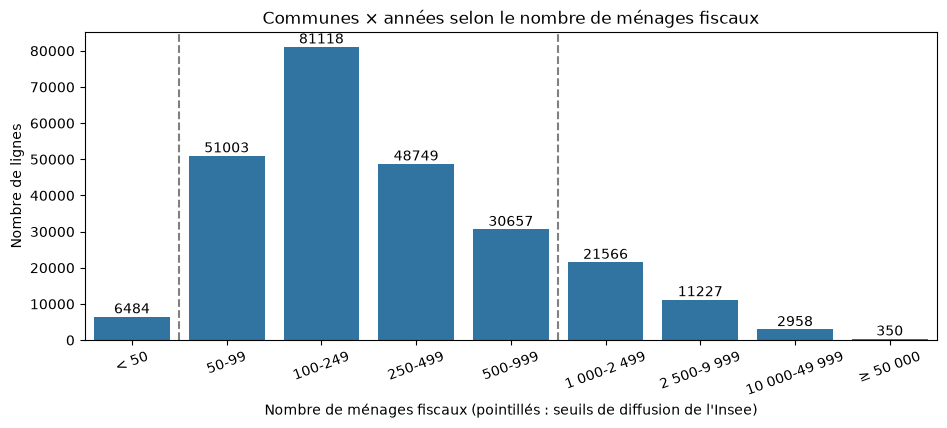

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Classes de plus en plus larges (logique logarithmique), en gardant les seuils Insee (50 et 1 000)
bornes = [0, 50, 100, 250, 500, 1000, 2500, 10_000, 50_000, float("inf")]
etiquettes = ["< 50", "50-99", "100-249", "250-499", "500-999",
              "1 000-2 499", "2 500-9 999", "10 000-49 999", "≥ 50 000"]

classes = pd.cut(df_num_discrete["NBMEN"], bins=bornes, labels=etiquettes, right=False)

fig, ax = plt.subplots(figsize=(11, 4))
sns.countplot(x=classes, ax=ax)
ax.bar_label(ax.containers[0])
ax.axvline(0.5, color="grey", ls="--")   # seuil de 50 ménages
ax.axvline(4.5, color="grey", ls="--")   # seuil de 1 000 ménages
ax.set_title("Communes × années selon le nombre de ménages fiscaux")
ax.set_xlabel("Nombre de ménages fiscaux (pointillés : seuils de diffusion de l'Insee)")
ax.set_ylabel("Nombre de lignes")
ax.tick_params(axis="x", rotation=20)
plt.show()

In [32]:
df_num_quanti.describe().T

,count,mean,std,min,25%,50%,75%,max
NBPERS,254112.0,2110.074865,15108.282799,74.000000,249.000000,523.000000,1268.000000,2.113228e+06
NBUC,254112.0,1448.706849,10772.384323,61.100000,169.600000,353.200000,855.400000,1.510801e+06
D1,42402.0,12703.124228,2107.883196,5480.400000,11172.371795,12695.166667,14153.189655,2.227000e+04
D2,42402.0,15677.321280,2549.302979,7207.000000,13900.000000,15590.000000,17340.000000,2.942000e+04
D3,42402.0,18008.365283,2907.058980,8460.400000,16030.000000,17850.000000,19768.048387,3.749000e+04
D4,42402.0,20135.558078,3269.273494,9588.000000,18000.000000,19831.666667,21900.000000,4.519000e+04
Q1,42402.0,16883.981361,2734.516511,7846.250000,14994.850000,16763.458075,18620.000000,3.300000e+04
niveau_vie_median,254112.0,21596.921833,3150.176027,9958.300000,19570.000000,21170.000000,23120.000000,5.534000e+04
Q3,42402.0,28924.599600,5579.870915,15265.714286,25430.000000,27750.000000,31037.821429,8.053000e+04
D6,42402.0,24539.589673,4278.255389,12376.190476,21793.857143,23800.000000,26440.000000,6.206000e+04


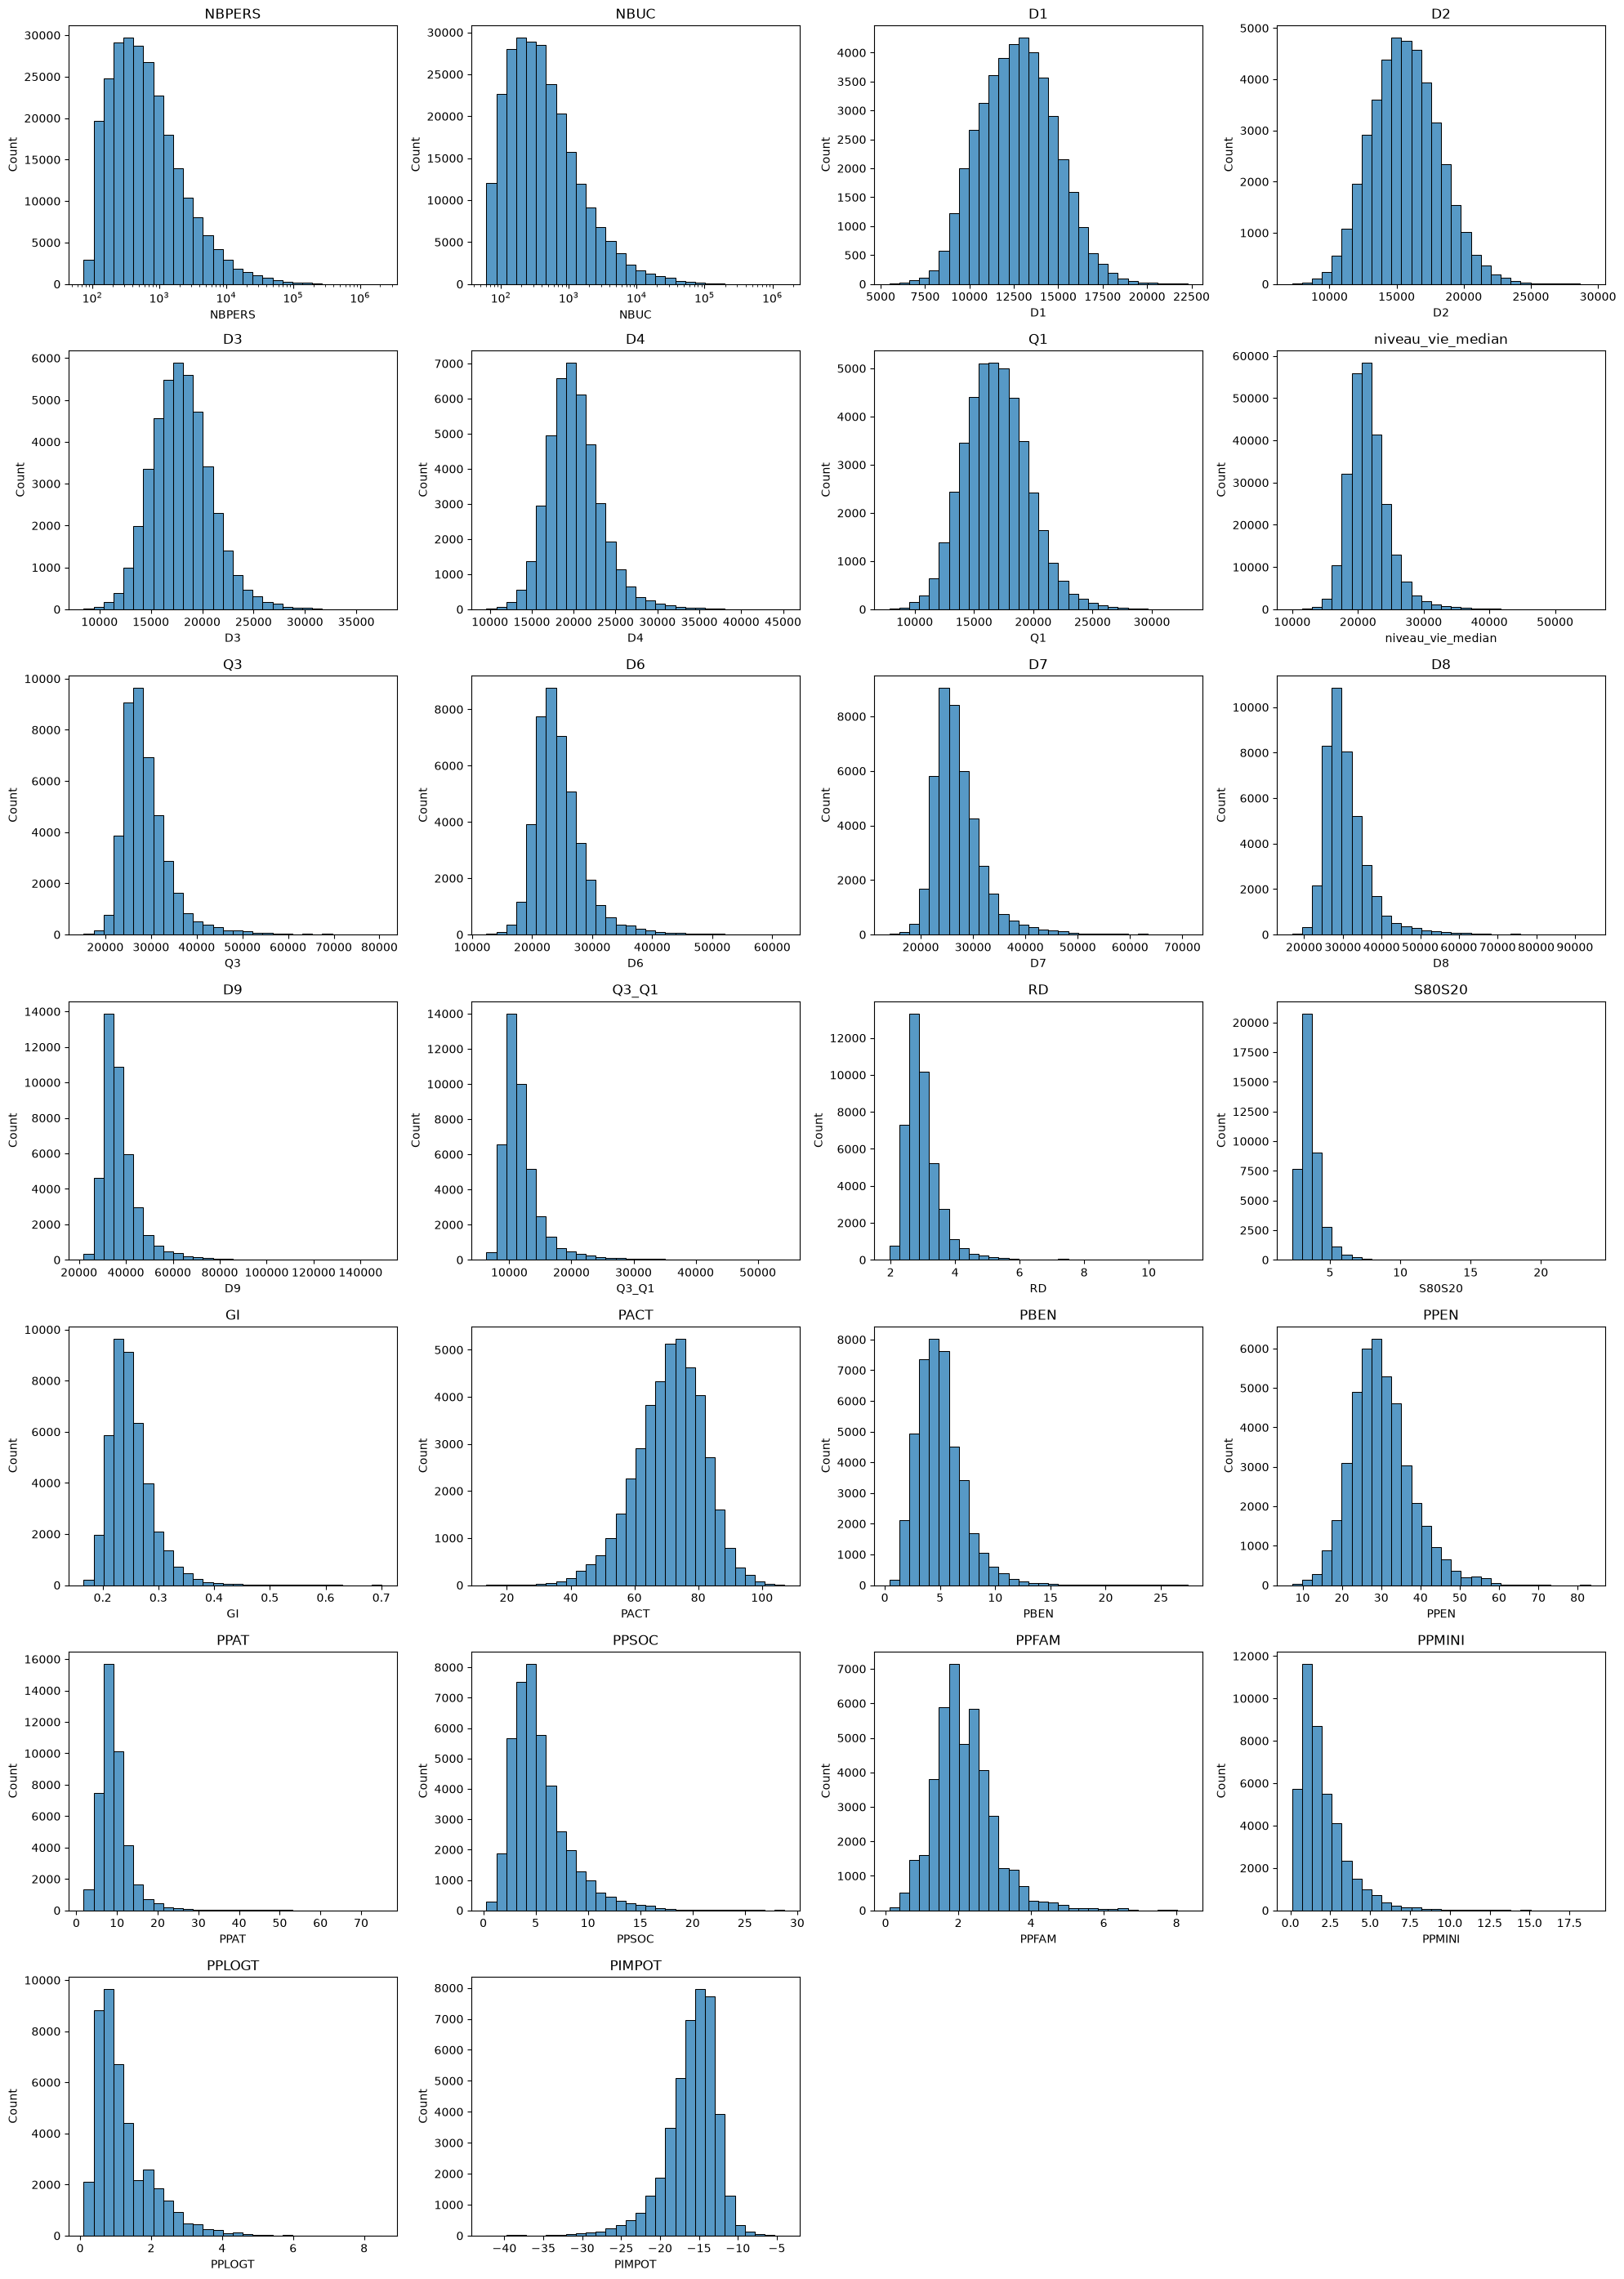

In [33]:
# Histogrammes des 26 variables continues (grille 7 × 4 = 28 cases)
fig, axes = plt.subplots(7, 4, figsize=(20, 28))
axes = axes.flatten()

for i, col in enumerate(df_num_quanti.columns):
    sns.histplot(
        data=df_num_quanti,
        x=col,
        bins=30,
        ax=axes[i],
        log_scale=(col in ["NBPERS", "NBUC"]),   # très asymétriques : échelle logarithmique
    )
    axes[i].set_title(col)

# Les 2 cases en trop restent vides
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

**Constat :**

*Variable discrète.* 

Les communes de 50 à 999 ménages représentent 83 % des lignes (211 527) ; 36 101 lignes comptent au moins 1 000 ménages et 6 484 moins de 50. Le nombre de lignes avec indicateurs détaillés (42 402) dépasse celui des communes d'au moins 1 000 ménages : la règle de diffusion porte sur 1 000 ménages **ou** 2 000 personnes.
La classe la plus fréquente est 100 à 249 ménages (81 118 lignes, environ 32 %) : la France est d'abord un pays de petites communes. Seules 350 lignes dépassent 50 000 ménages, soit une quarantaine de communes par an : les grandes villes, dont Paris, Lyon et Marseille, comptées à la fois en commune entière et par arrondissement

*Variables continues.*
- **Taille** (`NBPERS`, `NBUC`, en échelle logarithmique) : une majorité de petites communes (quelques centaines d'habitants) et quelques très grandes.
- **Niveau de vie** : la médiane se concentre entre 18 000 et 25 000 €, avec une queue vers la droite jusqu'à 55 000 €. D1 est presque symétrique, mais la queue à droite s'allonge à mesure qu'on monte dans les déciles (D9 jusqu'à 149 000 €) : les écarts entre communes se font surtout par le haut de la distribution.
- **Inégalités** (`Q3_Q1`, `RD`, `S80S20`, `GI`) : distributions très asymétriques à droite. La plupart des communes sont proches de la valeur centrale (Gini autour de 0,24), et quelques-unes sont très inégalitaires (Gini jusqu'à 0,70).
- **Composition du revenu** : `PACT` est asymétrique à gauche (des communes où les revenus d'activité pèsent peu) ; `PPEN` (jusqu'à 80 %) et `PPAT` (jusqu'à 75 %) ont des queues à droite, qui signalent des communes de retraités ou de patrimoine ; les prestations sociales (`PPSOC`, `PPMINI`, `PPLOGT`) ont des queues à droite, qui signalent des communes modestes ; `PIMPOT` s'étire vers les valeurs très négatives (communes aisées, plus imposées). L'histogramme de `PPFAM` est irrégulier (« en peigne ») parce que les parts sont arrondies à 0,1 point.

**Impact projet :**
- Les histogrammes des indicateurs détaillés ne portent que sur les communes les plus peuplées (environ 5 300 par an), pas sur la même population que la médiane : on ne peut pas les comparer directement.
- Plusieurs variables très asymétriques pourraient nécessiter une transformation (logarithme) en modélisation.

**Action envisagée :** identifier les communes situées dans les queues de distribution pour distinguer cas réels et erreurs (étape des valeurs extrêmes).

# C. Qualité

## 5.Doublons

**Objectif :** repérer les lignes copiées, qui gonflent les effectifs.


In [34]:
# 1. Doublons sur la clé commune × année
print("Doublons commune × année :", filo.duplicated(subset=["code_commune", "annee"]).sum())

# 2. Paris, Lyon, Marseille : commune entière vs somme des arrondissements
plm = {
    "Paris":     ("75056", "751"),   # code commune, début des codes d'arrondissement
    "Lyon":      ("69123", "6938"),
    "Marseille": ("13055", "132"),
}
f21 = filo[filo["annee"] == 2021]
for ville, (code, prefixe) in plm.items():
    commune = f21.loc[f21["code_commune"] == code, "NBMEN"].sum()
    arrond = f21[f21["code_commune"].str.startswith(prefixe)]
    print(f"{ville} 2021 | commune : {commune:,.0f} ménages | "
          f"{len(arrond)} arrondissements : {arrond['NBMEN'].sum():,.0f} ménages")

Doublons commune × année : 0
Paris 2021 | commune : 1,007,247 ménages | 20 arrondissements : 1,007,247 ménages
Lyon 2021 | commune : 230,041 ménages | 9 arrondissements : 230,041 ménages
Marseille 2021 | commune : 363,023 ménages | 16 arrondissements : 363,023 ménages


In [35]:
# Codes utilisés par DVF+ pour Paris, Lyon et Marseille
for dep in ["75", "69", "13"]:
    codes = pd.read_parquet(data / "dvf_plus_residentiel" / f"dvf_plus_d{dep}.parquet",
                            columns=["l_codinsee"])["l_codinsee"]
    ville = codes[codes.str.match(r"^(751|6938|132|75056|69123|13055)")]
    print(dep, sorted(ville.unique())[:5], "...", ville.nunique(), "codes")

75 ['75101', '75102', '75103', '75104', '75105'] ... 20 codes
69 ['69381', '69382', '69383', '69384', '69385'] ... 9 codes
13 ['13201', '13202', '13203', '13204', '13205'] ... 16 codes


**Constat :**

Aucun doublon exact et aucun doublon sur la clé commune × année.

En revanche, Paris, Lyon et Marseille sont présentes à deux niveaux : la commune entière (75056, 69123, 13055) et ses arrondissements (20, 9 et 16). Le nombre de ménages de la commune est exactement égal à la somme de ses arrondissements (en 2021 : 1 007 247 pour Paris, 230 041 pour Lyon, 363 023 pour Marseille). Les deux niveaux décrivent donc la même population : ce sont des doublons métier.

**Impact projet :** garder les deux niveaux compterait deux fois ces ménages et fausserait toute statistique nationale.

**Action envisagée :** DVF+ utilise les codes d'arrondissement (75101 à 75120, 69381 à 69389, 13201 à 13216). On garde donc les arrondissements et on retire les trois communes entières (75056, 69123, 13055) avant la jointure. À vérifier : le niveau utilisé par la table de passage commune → bassin de vie.

## 6. Valeurs manquantes

**Objectif :** mesurer l'ampleur des manquants par variable.




In [36]:
# Vérification des quantités de valeurs manquantes dans le dataset
missing = (filo.isna().mean() * 100).round(2)
missing = missing[missing > 0].sort_values(ascending=False)

display(missing)

D1                   83.77
D2                   83.77
D3                   83.77
D4                   83.77
D6                   83.77
D7                   83.77
D8                   83.77
D9                   83.77
GI                   83.77
PBEN                 83.77
PACT                 83.77
RD                   83.77
PPSOC                83.77
PIMPOT               83.77
PPAT                 83.77
PPFAM                83.77
PPEN                 83.77
PPLOGT               83.77
PPMINI               83.77
S80S20               83.77
Q3_Q1                83.77
Q1                   83.77
Q3                   83.77
NBPERS                2.76
NBMEN                 2.76
NBUC                  2.76
niveau_vie_median     2.76
dtype: float64

In [37]:
grande = (filo["NBMEN"] >= 1000) | (filo["NBPERS"] >= 2000)

display(pd.crosstab(
    grande.rename("≥ 1 000 ménages ou ≥ 2 000 personnes"),
    filo["D1"].isna().rename("D1 manquant"),
    margins=True
)
)
print("Les indicateurs détaillés manquent pour toutes les communes sous le seuil de 1 000 ménages ou 2 000 personnes, "
      "et sont publiés pour toutes les autres, à une exception près.")

D1 manquant,False,True,All
≥ 1 000 ménages ou ≥ 2 000 personnes,,,
False,0,218916,218916
True,42402,1,42403
All,42402,218917,261319


Les indicateurs détaillés manquent pour toutes les communes sous le seuil de 1 000 ménages ou 2 000 personnes, et sont publiés pour toutes les autres, à une exception près.


In [38]:
# Nombre d'indicateurs détaillés vides par ligne : 0 ou 23 si le masquage se fait en bloc
detail = [c for c in df_num_quanti.columns if c not in ["NBPERS", "NBUC", "niveau_vie_median"]]
display(filo[detail].isna().sum(axis=1).value_counts())
print("Les 23 indicateurs détaillés sont publiés ou masqués ensemble, jamais séparément.")

23    218917
0      42402
Name: count, dtype: int64

Les 23 indicateurs détaillés sont publiés ou masqués ensemble, jamais séparément.


**Constat :**

Les valeurs manquantes s'expliquent entièrement par le secret statistique de l'Insee :
- **médiane et effectifs** (`NBMEN`, `NBPERS`, `NBUC`, `niveau_vie_median`) : 2,76 % de manquants, uniquement sur les communes sous le seuil minimal, présentes vides dans les fichiers 2020 et 2021 ;
- **23 indicateurs détaillés** (déciles, quartiles, inégalités, composition du revenu) : 83,77 % de manquants. Ils sont publiés en bloc (0 ou 23 vides par ligne), pour toutes les communes d'au moins 1 000 ménages ou 2 000 personnes (une seule exception), et pour aucune autre.

Les manquants dépendent donc de la taille de la commune, une variable observée : mécanisme **MAR**.

**Impact projet :** la médiane couvre presque toutes les communes ; les indicateurs détaillés ne décrivent que les grandes communes et ne peuvent pas être imputés de façon fiable pour les autres.

**Action envisagée :** retenir la médiane comme indicateur principal de revenu ; décider en groupe de l'usage des indicateurs détaillés.

## 6 Distributions et valeurs extrêmes

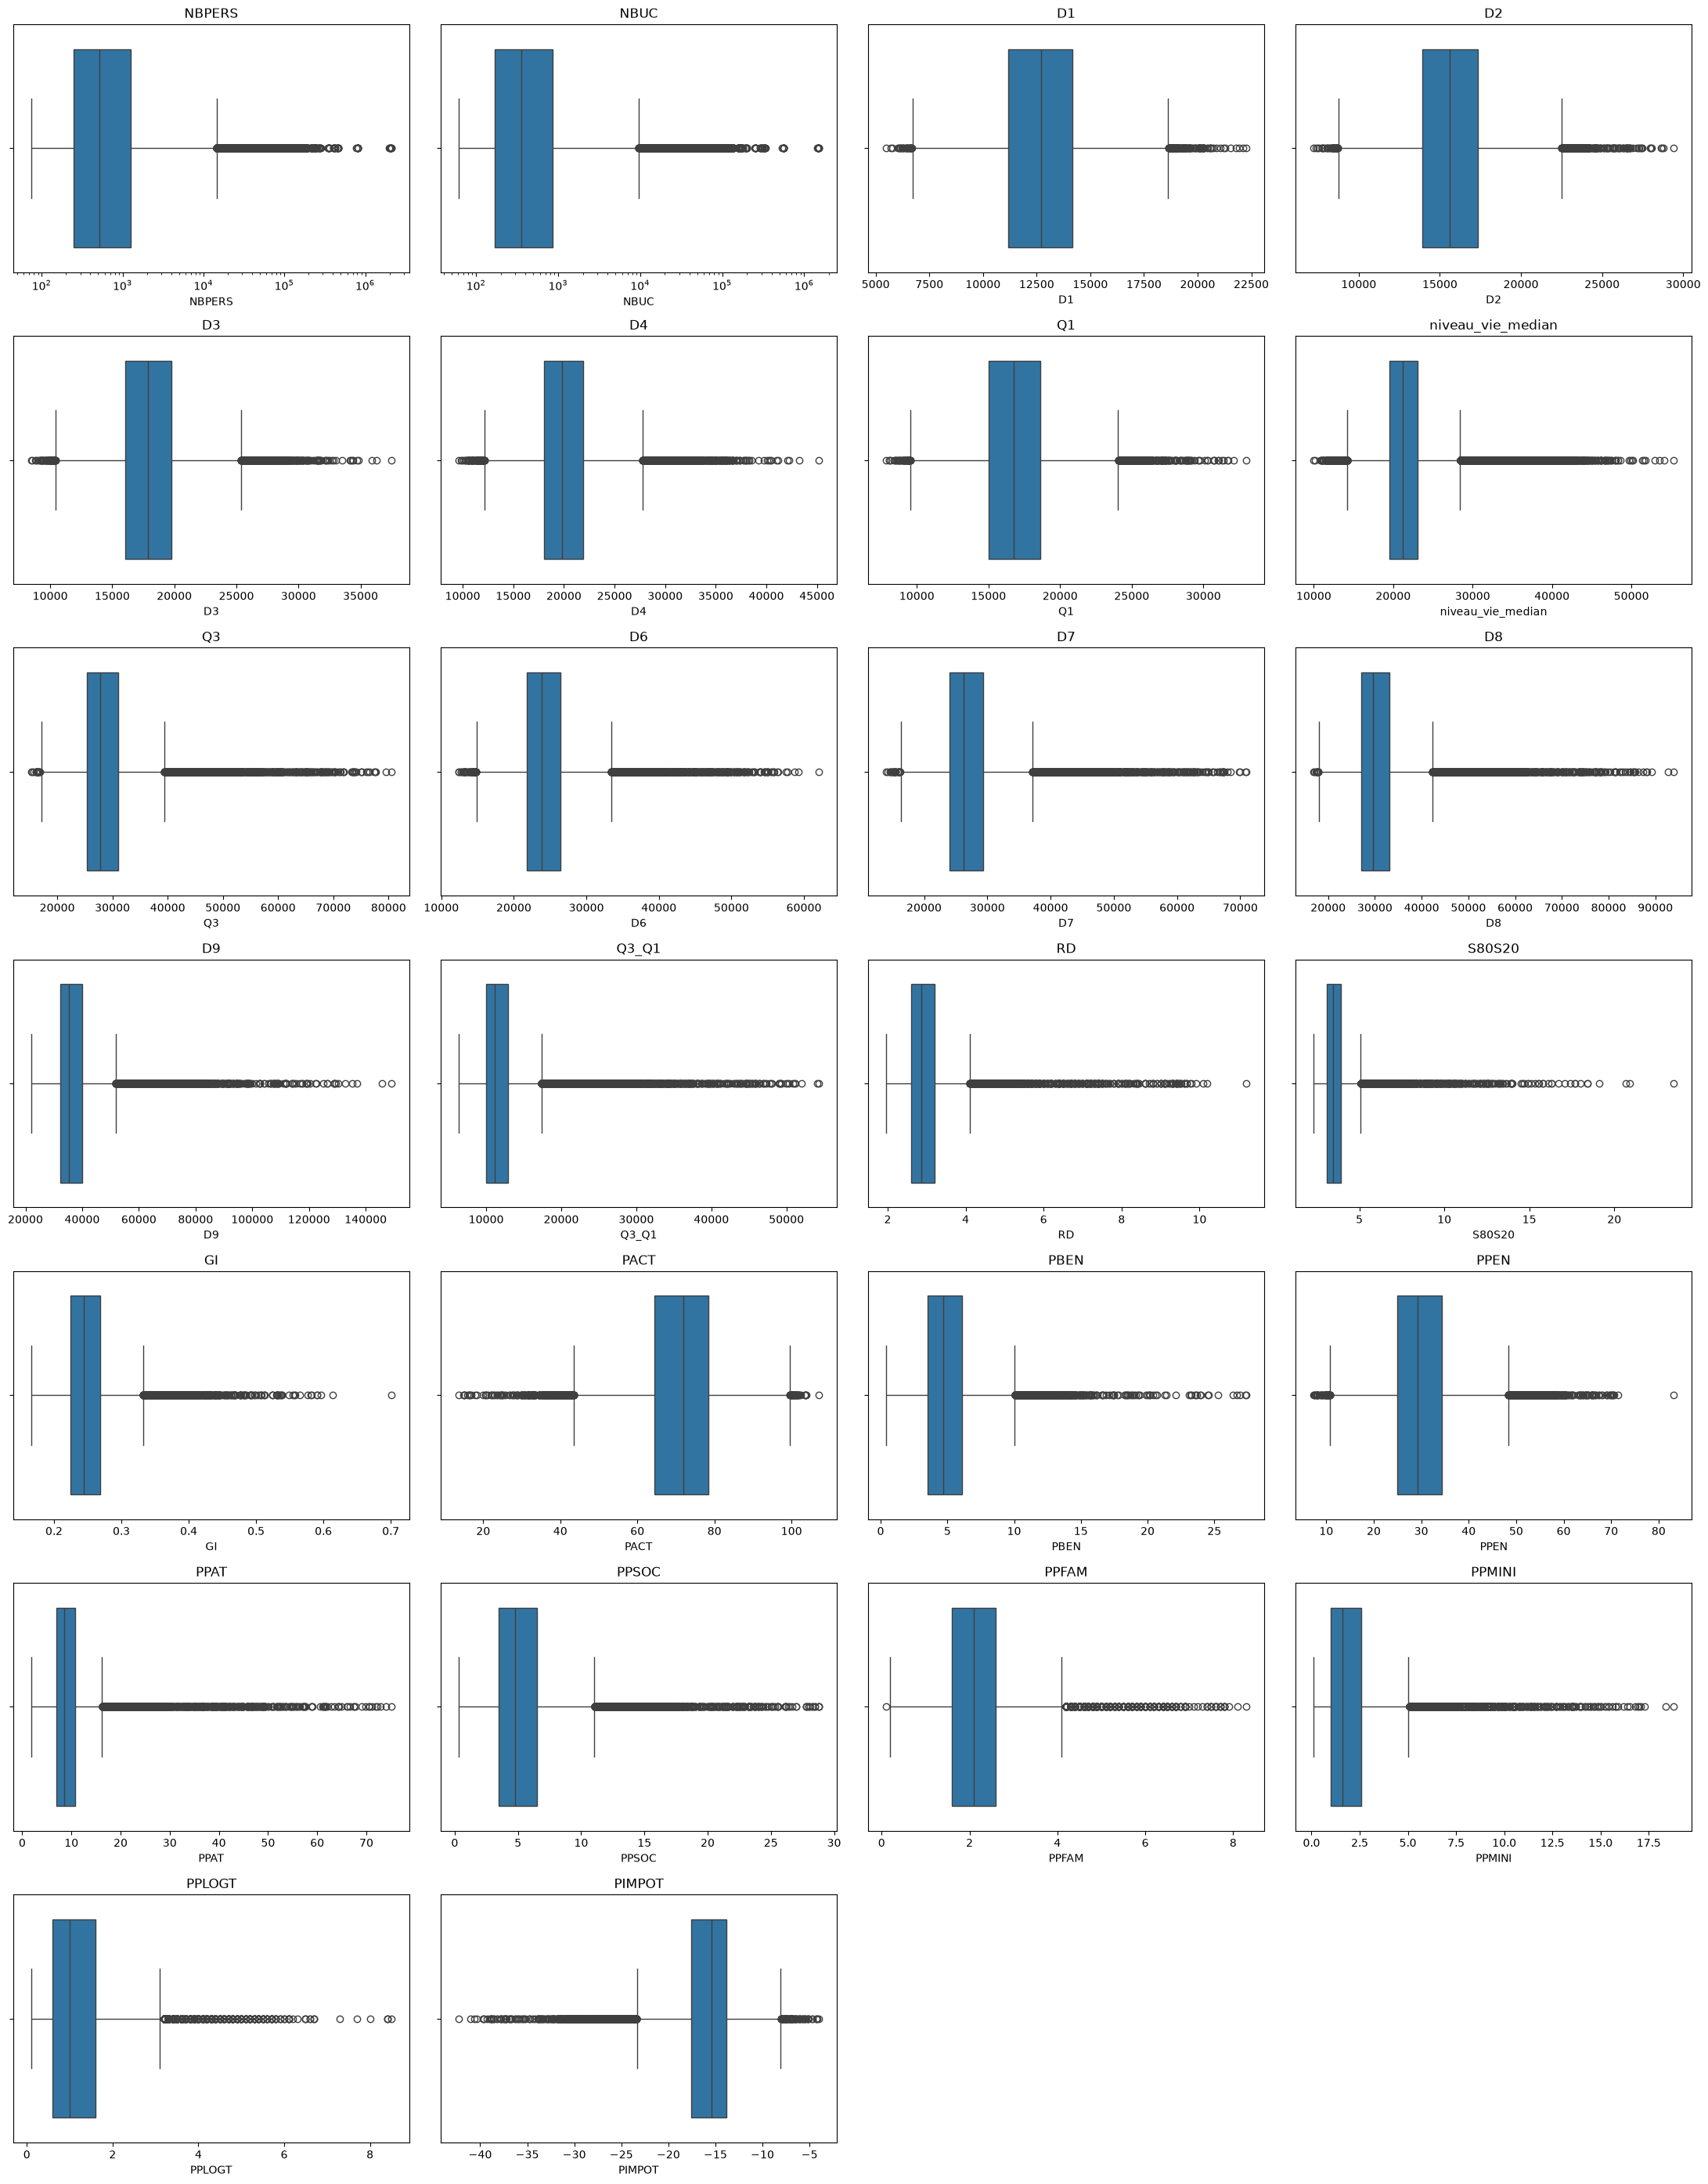

In [39]:
fig, axes = plt.subplots(7, 4, figsize=(22, 28))
axes = axes.flatten()

for i, col in enumerate(df_num_quanti.columns):
    sns.boxplot(
        data=df_num_quanti,
        x=col,
        ax=axes[i],
        log_scale=(col in ["NBPERS", "NBUC"]),
    )
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [40]:
# Position des valeurs extrêmes : comparaison du 99e centile et du maximum
quantiles = df_num_quanti.describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).T.round(2)
quantiles["max / p99"] = (quantiles["max"] / quantiles["99%"]).round(2)

display(quantiles[["min", "1%", "5%", "50%", "95%", "99%", "max", "max / p99"]])

,min,1%,5%,50%,95%,99%,max,max / p99
NBPERS,74.00,104.00,125.00,523.00,6616.45,28877.41,2113228.50,73.18
NBUC,61.10,72.00,86.60,353.20,4500.04,19548.50,1510801.25,77.28
D1,5480.40,8280.00,9360.00,12695.17,16179.73,17700.00,22270.00,1.26
D2,7207.00,10259.45,11710.00,15590.00,19960.00,22110.00,29420.00,1.33
D3,8460.40,11925.62,13610.00,17850.00,22930.00,26089.90,37490.00,1.44
D4,9588.00,13559.21,15460.00,19831.67,25760.00,30350.00,45190.00,1.49
Q1,7846.25,11096.91,12690.00,16763.46,21480.00,24140.00,33000.00,1.37
niveau_vie_median,9958.30,15824.03,17450.00,21170.00,27030.00,32240.00,55340.00,1.72
Q3,15265.71,20708.67,22820.00,27750.00,38563.80,50339.91,80530.00,1.60
D6,12376.19,17210.10,19360.00,23800.00,31960.00,39659.90,62060.00,1.56


In [41]:
# Les communes aux valeurs les plus isolées sont-elles les mêmes ?
cols_vue = ["code_commune", "annee", "NBMEN", "niveau_vie_median", "D9", "GI", "S80S20", "PPAT", "PIMPOT"]
display(filo.sort_values("S80S20", ascending=False)[cols_vue].head(30))

,code_commune,annee,NBMEN,niveau_vie_median,D9,GI,S80S20,PPAT,PIMPOT
226530,01160,2021,3704.0,27220.000000,73920.000000,0.581000,23.500000,5.4,-15.1
255681,75106,2021,16896.0,41750.000000,126350.000000,0.596000,20.900000,44.6,-35.8
255682,75107,2021,23791.0,45380.000000,149080.000000,0.591000,20.700000,43.2,-38.8
154796,75107,2018,24129.0,44490.000000,145730.000000,0.582000,19.100000,44.2,-42.3
123382,75107,2017,24290.0,43270.000000,132690.000000,0.577000,18.408000,33.2,-38.8
220752,75107,2020,24210.0,44110.000000,135220.000000,0.565000,18.400000,41.1,-40.4
255683,75108,2021,17615.0,44100.000000,130390.000000,0.557000,18.000000,35.7,-37.2
255691,75116,2021,74142.0,41550.000000,119190.000000,0.549000,17.700000,38.7,-35.5
224316,85284,2020,2109.0,22600.000000,35440.000000,0.701000,17.700000,4.4,-11.3
186153,75107,2019,24228.0,44400.000000,137020.000000,0.558000,17.400000,42.2,-41.0


In [42]:
# Série complète des deux communes suspectes
for code in ["01160", "85284"]:
    print(f"=== {code} ===")
    display(filo[filo["code_commune"] == code]
            [["annee", "NBMEN", "D1", "niveau_vie_median", "D9", "GI", "S80S20", "PBEN", "PPAT"]])

=== 01160 ===


,annee,NBMEN,D1,niveau_vie_median,D9,GI,S80S20,PBEN,PPAT
143,2014,3192.0,6680.000000,25135.333333,65116.666667,0.429955,12.561307,1.7,10.4
33115,2015,3278.0,6806.111111,25595.555556,67490.666667,0.440434,12.910957,1.6,10.6
65367,2016,3121.0,7311.500000,26579.333333,70676.923077,0.431709,12.536053,1.5,9.5
97156,2017,3158.0,7090.000000,26280.000000,68090.000000,0.431000,12.585000,1.5,9.7
128895,2018,3181.0,7530.000000,27650.000000,68910.000000,0.429000,12.000000,1.6,10.5
160225,2019,3535.0,7560.000000,26770.000000,70080.000000,0.444000,13.400000,1.6,9.0
191591,2020,3676.0,7060.000000,26970.000000,71260.000000,0.438000,13.200000,2.3,8.3
226530,2021,3704.0,6580.000000,27220.000000,73920.000000,0.581000,23.500000,1.2,5.4


=== 85284 ===


,annee,NBMEN,D1,niveau_vie_median,D9,GI,S80S20,PBEN,PPAT
30991,2014,1883.0,12208.0,20142.000000,33380.0,0.247484,3.431583,5.8,14.4
63272,2015,1915.0,12578.4,20566.833333,34986.0,0.250438,3.471669,6.9,14.6
95081,2016,1929.0,13068.0,21173.333333,34699.0,0.243418,3.336099,6.3,13.8
126824,2017,1961.0,12920.0,21420.000000,35980.0,0.245000,3.395000,6.2,12.9
158176,2018,2002.0,13290.0,21820.000000,36520.0,0.247000,3.400000,6.0,13.6
189538,2019,2033.0,13690.0,21970.000000,36120.0,0.249000,3.400000,5.8,13.7
224316,2020,2109.0,14290.0,22600.000000,35440.0,0.701000,17.700000,2.0,4.4
259246,2021,2139.0,14560.0,23260.000000,36640.0,0.259000,3.500000,5.3,14.1


**Constat :**

Les boîtes à moustaches signalent beaucoup de points au-delà des moustaches, ce qui est attendu sur 260 000 lignes et des distributions asymétriques. Le rapport entre le maximum et le 99e centile montre que la plupart des variables n'ont pas de valeur isolée (rapport de 1,1 à 1,7).

Les valeurs vraiment isolées sont de deux types :
- **des communes très aisées, cohérentes sur tous leurs indicateurs** : Paris 6e, 7e, 8e et 16e (D9 jusqu'à 149 000 €, revenus du patrimoine à 35-45 %, impôts jusqu'à −42 %), stables d'une année sur l'autre. Ce sont des cas réels ;
- **des pics ponctuels sur une seule année** : en 85284 (2020), le Gini passe de 0,25 à 0,70 et le S80/S20 de 3,4 à 17,7, puis reviennent à la normale l'année suivante, alors que D1, la médiane et D9 ne bougent pas. Un revenu exceptionnel perçu par un seul ménage suffit à faire exploser les indicateurs calculés sur des masses de revenus (Gini, S80/S20), sans modifier les déciles. Le même phénomène apparaît en 01160 en 2021, commune déjà très inégalitaire les autres années.

**Impact projet :** la médiane et les déciles sont robustes ; le Gini et le S80/S20 sont sensibles à un seul revenu exceptionnel dans les communes moyennes.

**Action envisagée :** aucune suppression à ce stade (données administratives, cas réels) ; privilégier la médiane et les déciles ; si le Gini ou le S80/S20 sont retenus, envisager un lissage sur plusieurs années.

# Synthèse du premier niveau d'audit — Filosofi

### Constat

La base Filosofi constitue une source pertinente pour décrire le revenu des habitants des communes. Produite par l'Insee à partir des déclarations fiscales et des prestations sociales, elle est administrative et exhaustive : elle ne repose ni sur une enquête ni sur des déclarations volontaires.

Les huit fichiers annuels (2014 à 2021) ont été assemblés en une seule base de **261 319 lignes (une commune × une année) et 29 variables**, en ne gardant que les variables présentes toutes les années. La part des revenus d'activité (`PACT`), absente en 2014, a été reconstruite à partir de deux autres variables, après vérification sur 2015.

L'examen de la base montre une qualité satisfaisante. Aucun doublon exact ni sur la clé commune × année n'a été détecté, et les valeurs sont cohérentes entre elles : les déciles sont bien ordonnés, les sous-parts des prestations sociales s'additionnent correctement et les impôts sont toujours négatifs.

Les valeurs manquantes s'expliquent entièrement par le **secret statistique** :
- la **médiane du niveau de vie** est disponible pour 31 300 à 33 000 communes par an, soit presque toutes ;
- les **23 indicateurs détaillés** (déciles, inégalités, composition du revenu) ne sont publiés que pour les communes d'au moins 1 000 ménages ou 2 000 personnes, soit environ 5 300 communes par an (16 % des lignes).

Les valeurs extrêmes correspondent surtout à des cas réels, comme les arrondissements les plus aisés de Paris. Quelques pics ponctuels du Gini et du S80/S20 montrent que ces deux indicateurs peuvent être perturbés par un seul revenu exceptionnel dans une commune moyenne, alors que la médiane et les déciles restent stables.

**Ce premier audit permet donc de retenir Filosofi comme source de variables explicatives**, avec trois limites :
- elle décrit les **habitants** d'une commune, pas les acheteurs de l'année ;
- les indicateurs détaillés ne couvrent que les grandes communes ;
- 2021 est le dernier millésime : l'Insee ne produira pas le millésime 2022.

### Rapprochement avec DVF+

La jointure avec DVF+ se fera par le code commune (`code_commune` dans Filosofi, `l_codinsee` dans DVF+) et l'année. Trois points devront être réglés auparavant :
- **Paris, Lyon et Marseille** sont présents à la fois en commune entière et par arrondissement, avec exactement les mêmes ménages. DVF+ utilisant les codes d'arrondissement, ce sont eux qui seront conservés.
- **Les codes communes changent entre millésimes** : chaque millésime est publié dans la géographie du 1er janvier de l'année suivante, et les fusions de communes modifient les codes. Une géographie de référence commune à toute l'équipe devra être fixée.
- **Le passage au bassin de vie** : les médianes communales ne s'additionnent pas. L'Insee publie directement Filosofi par bassin de vie (bassins 2022 à partir du millésime 2020), ce qui pourrait être une alternative à explorer.

Les années 2022 à 2025 de DVF+ n'auront pas de revenu correspondant : la manière de les traiter sera décidée en modélisation, seulement si l'EDA montre un lien entre revenu et prix.

### Décisions pour la suite

**Base retenue.** La base `filosofi_commune_2014_2021.parquet` (29 variables) est conservée telle quelle pour l'EDA. Aucune valeur n'est supprimée ni imputée.

**Paris, Lyon, Marseille.** Les arrondissements sont conservés ; les communes entières (75056, 69123, 13055) seront retirées avant la jointure.

**Variables : pistes à discuter en groupe.**
- La **médiane du niveau de vie** est l'indicateur principal : elle couvre presque toutes les communes et reste stable.
- Les **indicateurs détaillés** ne couvrent que les grandes communes. Ils ne pourront servir que sur ce sous-ensemble, ou à la maille bassin de vie. Ils ne doivent pas être imputés pour les autres communes, puisque leur absence est voulue par l'Insee.
- Le **Gini et le S80/S20** sont sensibles aux revenus exceptionnels : à privilégier, si besoin, sous forme lissée sur plusieurs années.
- Les trois effectifs (`NBMEN`, `NBPERS`, `NBUC`) portent probablement la même information : leur redondance sera vérifiée en EDA.

**Contrôles à venir.** L'EDA portera sur le lien entre le revenu des communes et le prix au m², sur les années communes aux deux sources (2014-2021).

À ce stade, aucun nettoyage n'est engagé. L'audit fournit une connaissance suffisante de la structure, du contenu et des limites de la base pour passer à l'EDA.